# Phi-3 · Aprendizaje por retroalimentación humana

DistilBERT estima cuál de dos respuestas para la misma solicitud se ajusta mejor a las preferencias de HH-RLHF. A partir del adaptador SFT de Phi-3, PPO optimiza esa señal con una penalización por alejarse de la política de referencia. El cuaderno de [evaluación](evaluacion.ipynb) compara la política resultante con zero-shot, few-shot y SFT.

Usa el kernel **Tarea 3 (GPU)** o **rocm (3.14.10)** en VS Code. El [entrenamiento SFT](entrenamiento.ipynb) debe haber guardado el adaptador en `salidas/sft_lr5e5/`.

In [1]:
from pathlib import Path
import sys

folder = Path.cwd() if Path("comun.py").is_file() else Path.cwd() / "tarea3"
if not (folder / "comun.py").is_file():
    raise FileNotFoundError("Abre el cuaderno desde la carpeta tarea3 o la raiz del repositorio.")
sys.path.insert(0, str(folder))

from comun import preparar_notebook

preparar_notebook()

Python del cuaderno: C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\.runtime\rocm\Scripts\python.exe


In [2]:
import os

from IPython.display import Markdown, display

from comun import OUT, SFT_DIR
from rlhf import clear_gpu, read_partitions, train_ppo, train_reward

PILOTO = os.getenv("TAREA3_PILOTO") == "1"
if not (OUT / SFT_DIR / "adapter_model.safetensors").is_file():
    raise FileNotFoundError("Ejecuta el entrenamiento SFT completo antes de iniciar RLHF.")

particiones, huellas = read_partitions(PILOTO)
print("Modo:", "piloto" if PILOTO else "final")
for nombre in ("sft", "recompensa_train", "recompensa_val", "ppo"):
    print(f"{nombre}: {len(particiones[nombre])} filas")

Modo: final
sft: 512 filas
recompensa_train: 1024 filas
recompensa_val: 128 filas
ppo: 128 filas


## Modelo de recompensa

Para cada solicitud se puntúan por separado la respuesta preferida y la rechazada. La pérdida es $-\log\sigma(r_\mathrm{preferida}-r_\mathrm{rechazada})$. El máximo es de 512 tokens por par solicitud–respuesta y se reservan hasta 128 para la solicitud. La validación usa pares de `test` de ambas fuentes. Se selecciona la época con mayor precisión de preferencia y se desempata por pérdida de validación.

La normalización de la recompensa usa la media y desviación de las respuestas de entrenamiento puntuadas por ese checkpoint.

In [3]:
import torch

torch.set_num_threads(min(torch.get_num_threads(), 8))
ruta_recompensa, recompensa = train_reward(particiones, huellas, PILOTO)
clear_gpu()
print(ruta_recompensa)

Reutilizando recompensa en C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\salidas\recompensa_distilbert
C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\salidas\recompensa_distilbert


Época seleccionada: 1
Recortes: {'train': {'pares_prompt_truncado': 2, 'preferidas_truncadas': 1, 'rechazadas_truncadas': 0}, 'val': {'pares_prompt_truncado': 0, 'preferidas_truncadas': 0, 'rechazadas_truncadas': 0}}


| Fuente | Pares | Precisión | Empates | Pérdida |
|---|---:|---:|---:|---:|
| Total | 128 | 62.5% | 0 | 0.6852 |
| helpful-base | 64 | 73.4% | 0 | 0.6623 |
| harmless-base | 64 | 51.6% | 0 | 0.7081 |

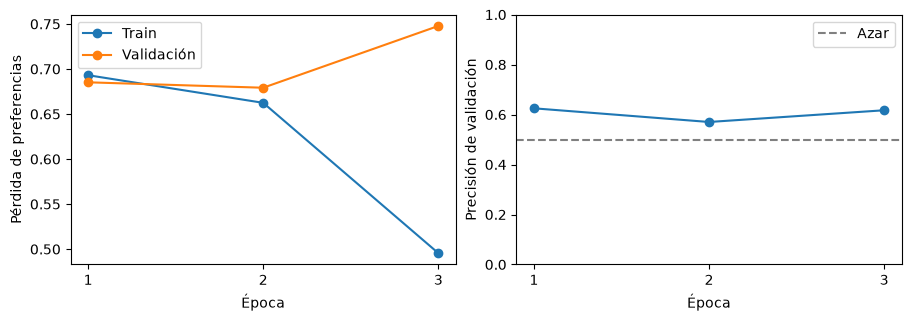

In [4]:
import matplotlib.pyplot as plt

validacion = recompensa["validacion"]
filas = [
    "| Fuente | Pares | Precisión | Empates | Pérdida |",
    "|---|---:|---:|---:|---:|",
]
por_fuente = {"Total": validacion, **validacion["por_fuente"]}
for fuente in por_fuente:
    metricas = por_fuente[fuente]
    filas.append(f"| {fuente} | {metricas['pares']} | {metricas['accuracy']:.1%} | "
                 f"{metricas['empates']} | {metricas['loss']:.4f} |")
display(Markdown("\n".join(filas)))
print(f"Época seleccionada: {recompensa['mejor_epoca']}")
print("Recortes:", recompensa["recortes"])

historial = recompensa["historial"]
epocas = [fila["epoca"] for fila in historial]
fig, (ax_loss, ax_acc) = plt.subplots(1, 2, figsize=(9, 3.1), layout="constrained")
ax_loss.plot(epocas, [fila["loss_train"] for fila in historial], "o-", label="Train")
ax_loss.plot(epocas, [fila["loss"] for fila in historial], "o-", label="Validación")
ax_loss.set(xlabel="Época", ylabel="Pérdida de preferencias", xticks=epocas)
ax_loss.legend()
ax_acc.plot(epocas, [fila["accuracy"] for fila in historial], "o-")
ax_acc.axhline(.5, color="0.5", linestyle="--", label="Azar")
ax_acc.set(xlabel="Época", ylabel="Precisión de validación", xticks=epocas, ylim=(0, 1))
ax_acc.legend()
plt.show()

## Optimización PPO

La política y la referencia comienzan con los mismos pesos SFT y comparten Phi-3 cuantizado. Se muestrea una respuesta por solicitud. PPO aplica la recompensa normalizada al último token y descuenta, en cada acción, la diferencia entre el logaritmo de la probabilidad de la política anterior y el de la referencia. Se usa GAE con $\gamma=1$ y $\lambda=0.95$, con valor futuro cero al terminar por EOS o por el límite. La pérdida de política y la de valor usan clipping de 0,2.

Cada lote mezcla dos solicitudes de cada fuente y se actualiza durante dos épocas. La corrida final usa 128 solicitudes y un máximo de 64 tokens por respuesta de entrenamiento. El piloto usa cuatro solicitudes, un máximo de 32 tokens y salidas propias. Si se interrumpe una corrida, vuelve a ejecutar la celda para retomar desde el último checkpoint compatible.

In [5]:
ruta_ppo, reporte_ppo = train_ppo(particiones, huellas, ruta_recompensa, recompensa, PILOTO)
clear_gpu()
print(ruta_ppo)

Reutilizando adaptador PPO completo en C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\salidas\ppo_lr3e6
C:\Users\diego\Documents\GitHub\DeepLearning\tarea3\salidas\ppo_lr3e6


Lotes: 32 · Respuestas muestreadas: 128 · Vacías: 2
Referencia intacta: True · Política actualizada: True · Valor actualizado: True


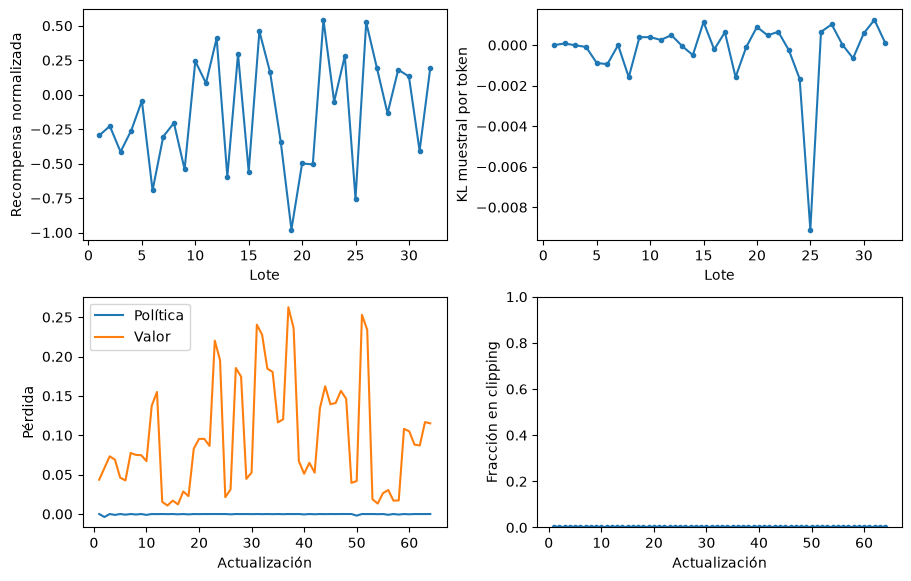

In [6]:
lotes = reporte_ppo["historial"]
pasos = [fila["lote"] for fila in lotes]
fig, axes = plt.subplots(2, 2, figsize=(9, 5.7), layout="constrained")
for ax, campo, nombre in zip(
    (axes[0, 0], axes[0, 1]), ("recompensa_normalizada", "kl_por_token"),
    ("Recompensa normalizada", "KL muestral por token"), strict=True,
):
    ax.plot(pasos, [fila[campo] for fila in lotes], ".-")
    ax.set(xlabel="Lote", ylabel=nombre)
actualizaciones = [u for lote in lotes for u in lote["actualizaciones"]]
pasos_ppo = range(1, len(actualizaciones) + 1)
axes[1, 0].plot(pasos_ppo, [u["loss_politica"] for u in actualizaciones], label="Política")
axes[1, 0].plot(pasos_ppo, [u["loss_valor"] for u in actualizaciones], label="Valor")
axes[1, 0].set(xlabel="Actualización", ylabel="Pérdida")
axes[1, 0].legend()
axes[1, 1].plot(pasos_ppo, [u["fraccion_clip"] for u in actualizaciones], ".-")
axes[1, 1].set(xlabel="Actualización", ylabel="Fracción en clipping", ylim=(0, 1))
plt.show()
print(f"Lotes: {len(lotes)} · Respuestas muestreadas: "
      f"{sum(len(fila['prompts']) for fila in lotes)} · Vacías: {sum(fila['vacias'] for fila in lotes)}")
print(f"Referencia intacta: {reporte_ppo['referencia_intacta']} · "
      f"Política actualizada: {reporte_ppo['politica_actualizada']} · "
      f"Valor actualizado: {reporte_ppo['valor_actualizado']}")

## Lectura de resultados

La precisión indica qué tan seguido el modelo de recompensa ordena correctamente los pares de validación. Las curvas PPO describen la señal que optimizó la política durante el muestreo. En la [evaluación comparativa](evaluacion.ipynb), Toxic-BERT puntúa las respuestas y la revisión humana mide seguridad, utilidad y rechazos innecesarios con los mismos prompts para las cuatro configuraciones.

Referencias metodológicas. [HH-RLHF](https://huggingface.co/datasets/Anthropic/hh-rlhf), [PPO](https://arxiv.org/abs/1707.06347) y [GAE](https://arxiv.org/abs/1506.02438).